# Reto 7: Detector de Regímenes de Mercado
## Comparativa entre activos: los modelos A y B en el S&P 500 y en otros cuatro índices (v7)

**Equipo:** Samuel Gómez Jiménez (744337) · Ana Paula Moreno Haro (744069) · Andrea Santoyo Vega (744585)
Laboratorio de Desarrollo de Soluciones Tecnológicas · ITESO · Otoño 2026

### De qué trata

El examen del tramo reservado (notebook `02_Examen_Reservado_SP500`) dice si los modelos A y B funcionan con datos nuevos **del mismo mercado** con el que se diseñaron. Este notebook hace una pregunta distinta: **¿funcionan en mercados que nunca vimos?** Es la prueba de varios mercados de Bulla et al. [9], que evaluaron su estrategia de regímenes en cinco índices de EUA, Alemania y Japón.

Este notebook no sustituye al examen del S&P. Es una prueba de robustez, y se presenta aparte. Pone los cinco índices lado a lado **en el tramo fuera de muestra (2022 – septiembre 2026)**, el S&P con las cifras del examen, para responder tres cosas:

1. **Cómo evoluciona el valor del portafolio** con A, B y comprar y mantener en cada índice (B.1).
2. **Qué tan bien le va a cada modelo frente a comprar y mantener**, con las métricas usuales: Sharpe, Sortino, volatilidad, caída máxima, Calmar (B.2 y B.3).
3. **Qué patrones se repiten de un mercado a otro y por qué** (B.4 y sección C).

### Organización

- **A. Preparación:** configuración, datos, calibración de cada índice (con el control del S&P) y la estimación móvil.
- **B. Comparativa de los cinco índices en el tramo fuera de muestra:** evolución del valor, caídas, tabla de métricas, diferencias contra comprar y mantener y patrones.
- **C. Por qué:** la escala de cada mercado, la premisa de Moreira y Muir y los episodios de caída, todo en el tramo fuera de muestra.
- **D. Hipótesis y conclusiones:** veredicto con prueba de signos y la guía para la lectura.

### Qué queda congelado y qué se recalibra

Los umbrales del modelo A (9.0% y 16.4%) y la volatilidad objetivo del modelo B (13.5%) están en la escala del S&P 500. Aplicados tal cual a un índice más volátil, A pasaría casi todo el tiempo fuera del mercado y la prueba no diría nada. Por eso **se congela el procedimiento, no las cifras**:

| | Igual que en el S&P (Reporte 5) | Se calcula para cada activo con la misma regla |
|---|---|---|
| Detector | HMM t, N = 3; ventana móvil de 2,000 días; reestimación cada 21 días; semilla 2026 | — |
| Ejecución | Rezago de un día; costo de 0.1% por unidad de \|Δw\|; T-bill para lo no invertido | — |
| Modelo A | Alcista y base 100%, bajista T-bills; 3 días para salir, 1 para volver | Umbrales = media geométrica de las volatilidades de regímenes vecinos del HMM de **su** periodo de estimación |
| Modelo B | w = min(σ* / σ̂, 1); banda de 10 puntos | σ* = volatilidad realizada (desv. estándar de los log-rendimientos × √252) de **su** periodo de estimación, redondeada a 0.1 puntos |

**Control.** La sección A.4 aplica el mismo procedimiento al S&P 500 y verifica que reproduzca las cifras del Reporte 5 (σ* = 13.5%, umbrales 9.0% y 16.4%). Si no las reproduce, el procedimiento no es el mismo y el notebook se detiene.

### Activos y partición de los datos (declarados antes de correr)

| Activo | Ticker | Por qué |
|---|---|---|
| Nasdaq Composite | `^IXIC` | Mismo mercado que el S&P, más volátil y concentrado en tecnología |
| IPC (México) | `^MXX` | Mercado emergente; antecedente de Climent Hernández et al. [8] |
| DAX (Alemania) | `^GDAXI` | Replica uno de los mercados de Bulla et al. [9] |
| Nikkei 225 (Japón) | `^N225` | Caída larga de 1990–2012: pone a prueba que el detector mide volatilidad, no dirección |

- **Estimación** (el equivalente a 1950–1989): todo lo anterior a 1990, con un mínimo de 10 años. Si el activo empieza después de 1980, la estimación abarca sus primeros 10 años.
- **Desarrollo:** del día siguiente al fin de la estimación hasta el 31 de diciembre de 2021. Aquí el detector empieza su cadena de reestimaciones mensuales para llegar a 2022 exactamente como el S&P. **Sus resultados no se muestran:** coincide en el tiempo con el periodo en que se diseñaron las reglas, así que no es una prueba limpia.
- **Reservado (fuera de muestra):** del primer día hábil de 2022 de cada bolsa al 30 de septiembre de 2026, el mismo tramo que el examen del S&P. **Es el único tramo que se reporta:** fuera del activo y fuera del periodo. Los umbrales y σ* se fijan sólo con la estimación, y el detector se reestima cada mes con los 2,000 días anteriores sin cortes desde el desarrollo, igual que el S&P en el examen.

### Hipótesis (declaradas antes de correr; se evalúan con costos)

| | Hipótesis | Criterio en cada activo |
|---|---|---|
| HM1 | B reduce la volatilidad | Volatilidad anual de B menor que la del índice |
| HM2 | B reduce la caída máxima | Caída máxima de B menos severa que la del índice |
| HM3 | B no sacrifica rendimiento ajustado por riesgo | La diferencia de Sharpe B − índice no es negativa con p < 0.05 (Ledoit y Wolf [16]) |
| HM4 | A reduce el riesgo | Volatilidad **y** caída máxima de A menores que las del índice |
| HM5 | B es al menos tan bueno como A | Sharpe de B ≥ Sharpe de A |

**Cómo se juntan los activos.** Para cada hipótesis se cuenta en cuántos activos se cumple y se calcula una **prueba de signos**: la probabilidad de que se cumpla en tantos activos o más si cada resultado fuera un volado. En el tramo reservado entran los cinco índices (el S&P sale del examen, `resultados_reservado_v7.pkl`). Que se cumpla en los cinco da p = 0.031. Es una prueba de poco poder, y lo declaramos de antemano. Los índices se mueven juntos, así que los cinco resultados no son del todo independientes, y el p es optimista.

### Limitaciones declaradas

- **Tasa libre de riesgo.** Para todos se usa el T-bill de EUA. Para el IPC eso **castiga** a A y B, porque los CETES pagaron más que el T-bill casi todo el periodo. Para el Nikkei y el DAX los **favorece**, porque las tasas de Japón y de Alemania fueron cercanas a cero o negativas.
- **Moneda local.** Los rendimientos están en la moneda de cada índice, sin cobertura cambiaria.
- **Dividendos.** `^IXIC`, `^MXX` y `^N225` son índices de precio, como `^GSPC`. El DAX es un índice de rendimiento total: reinvierte dividendos. Eso sube el rendimiento del DAX frente a los otros índices, pero no cambia la comparación entre estrategias dentro del DAX.
- **Calendarios.** Cada índice usa sus propios días hábiles; el rezago de ejecución se cuenta en ellos.
- **Costos.** 0.1% puede quedarse corto para un mercado emergente. No se cambia, para no tocar la regla, pero la rotación se reporta y se puede recalcular el costo.

### Cómo correrlo

Es el **tercero** en el orden de corrida. Necesita `resultados_reservado_v7.pkl`, que deja `02_Examen_Reservado_SP500` en la misma carpeta (sin ese archivo se detiene). No necesita `resultados_v5.pkl`. Guarda las figuras en `figuras/` (PNG a 200 dpi, listas para el paper) y las tablas en `tablas/` (CSV). La primera corrida estima el detector unas 300 a 450 veces por activo; el control del S&P y las cuatro estimaciones móviles pueden tardar más de una hora. Los resultados se guardan en `cache_multiactivo/` y una segunda corrida tarda segundos. Cada corrida queda anotada en `aperturas_multiactivo.log`.

# A. Preparación (técnica)
## A.1 Configuración

Todo lo que aparece aquí se fija antes de ver cualquier resultado. `CONFIG` copia los valores del v5.1 que usa el detector; `MODELOS` copia los del v6.1, salvo las dos cifras que ahora se calculan con una regla. La huella de la declaración resume todo lo anterior, incluidas las hipótesis.

In [18]:
import hashlib, json, os, pickle, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
from IPython.display import display
import yfinance as yf
warnings.filterwarnings("ignore", category=RuntimeWarning)

CONFIG = {                                              # del v5.1, sin cambios
    "ticker_tasa": "^IRX", "inicio": "1950-01-01", "fin": "2026-09-30", "inicio_reservado": "2022-01-01",
    "N": 3, "dist": "t", "n_inicializaciones": 10, "acotar_extremos": 6,
    "ventana": 2000, "reestimar_cada": 21, "reinicios_cada": 126, "rezago": 1, "semilla": 2026,
}
MODELOS = {                                             # del v6.1; las cifras de escala se sustituyen por reglas
    "inversion_inicial": 1000, "costo": 0.001, "horizonte": 1 + CONFIG["rezago"],
    "umbrales": "media geométrica de las volatilidades de regímenes vecinos del HMM del periodo de estimación del activo",
    "A": {"posicion": {"alcista": 1.0, "base": 1.0, "bajista": 0.0}, "dias_salir": 3, "dias_volver": 1},
    "B": {"vol_objetivo": "volatilidad realizada del periodo de estimación del activo, redondeada a 0.1 puntos",
          "tope": 1.0, "banda": 0.10},
}
REGLA_ESTIMACION = {"fin_minimo": "1989-12-31", "anios_minimos": 10}
ACTIVOS = {"^IXIC": "Nasdaq Composite", "^MXX": "IPC (México)", "^GDAXI": "DAX (Alemania)", "^N225": "Nikkei 225 (Japón)"}
CONTROL = {"ticker": "^GSPC", "nombre": "S&P 500", "vol_objetivo": 0.135, "umbrales": [0.090433, 0.163969]}   # Reporte 5
HIPOTESIS_M = {
    "HM1": "B reduce la volatilidad: volatilidad anual de B menor que la del índice",
    "HM2": "B reduce la caída máxima: caída máxima de B menos severa que la del índice",
    "HM3": "B no sacrifica Sharpe: la diferencia B − índice no es negativa con p menor que 0.05 (Ledoit y Wolf)",
    "HM4": "A reduce el riesgo: volatilidad y caída máxima de A menores que las del índice",
    "HM5": "B es al menos tan bueno como A: Sharpe de B mayor o igual que el de A",
}
CRITERIOS = {"alfa": 0.05, "caida_episodio": 0.10, "dias_rebote": 63}
CACHE = "cache_multiactivo"

DECLARACION = {"CONFIG": CONFIG, "MODELOS": MODELOS, "REGLA_ESTIMACION": REGLA_ESTIMACION, "ACTIVOS": ACTIVOS,
               "HIPOTESIS": HIPOTESIS_M, "CRITERIOS": CRITERIOS}
huella_decl = hashlib.md5(json.dumps(DECLARACION, sort_keys=True, ensure_ascii=False).encode()).hexdigest()[:10]

N, DIST, SEM = CONFIG["N"], CONFIG["dist"], CONFIG["semilla"]
NOMBRES = ["alcista", "base", "bajista"]
INICIAL, COSTO, H = MODELOS["inversion_inicial"], MODELOS["costo"], MODELOS["horizonte"]
POS_A = np.array([MODELOS["A"]["posicion"][n] for n in NOMBRES])
pB = MODELOS["B"]
ESTRATEGIAS = ["Comprar y mantener", "Modelo B", "Modelo A"]
PARES_M = [("Modelo B", "Comprar y mantener"), ("Modelo A", "Comprar y mantener"), ("Modelo A", "Modelo B")]

C_EST = {"Modelo A": "#08306b", "Modelo B": "#c2185b", "Comprar y mantener": "#52514e"}
C_REG = {"alcista": "#1baf7a", "base": "#a3a29c", "bajista": "#e34948"}
plt.rcParams.update({"figure.figsize": (12, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e3", "axes.titleweight": "bold",
                     "axes.titlesize": 12, "font.size": 10, "legend.frameon": False})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
print(f"Huella de la declaración: {huella_decl} | activos: {', '.join(ACTIVOS.values())} | "
      f"modelo: HMM {DIST}, N = {N} | Python {sys.version.split()[0]}")

Huella de la declaración: b6c45e4b6d | activos: Nasdaq Composite, IPC (México), DAX (Alemania), Nikkei 225 (Japón) | modelo: HMM t, N = 3 | Python 3.12.10


## A.2 Funciones

Las funciones del HMM, de las reglas A y B, de la volatilidad pronosticada, de las métricas y de la prueba pareada se copian **sin cambios** del v6.1. Sólo cambia cómo se les pasan los datos: en el v6.1 había un solo activo y los datos eran variables globales; aquí cada activo lleva los suyos.

In [19]:
# ---- Copiadas del v6.1 sin cambios ----
def acotar_extremos(v, k=6):
    if k is None:
        return v
    m, s = v.mean(), v.std()
    return np.clip(v, m - k * s, m + k * s)


def nombres_regimen(N):
    return ["alcista", "base", "bajista"] if N == 3 else ["alcista", "bajista"]


def densidades(x, mu, sigma, nu, dist):
    z = (x[:, None] - mu) / sigma
    if dist == "normal":
        return stats.norm.pdf(z) / sigma + 1e-300
    return stats.t.pdf(z, df=nu) / sigma + 1e-300


def forward(dens, A, pi):
    T, N = dens.shape
    alfa, c = np.zeros((T, N)), np.zeros(T)
    a = pi * dens[0]
    c[0] = a.sum(); alfa[0] = a / c[0]
    for t in range(1, T):
        a = (alfa[t - 1] @ A) * dens[t]
        c[t] = a.sum(); alfa[t] = a / c[t]
    return alfa, c, np.log(c).sum()


def backward(dens, A, c):
    T, N = dens.shape
    beta = np.ones((T, N))
    for t in range(T - 2, -1, -1):
        beta[t] = (A @ (dens[t + 1] * beta[t + 1])) / c[t + 1]
    return beta


def ajustar_hmm(x, N, dist="t", semilla=0, inicio=None, pesos=None, max_iter=500, tol=1e-7):
    rng = np.random.default_rng(semilla)
    w = np.ones(len(x)) if pesos is None else pesos
    if inicio is None:
        sigma = np.sort(x.std() * rng.uniform(0.4, 1.6, N))
        mu = rng.normal(0, x.std() * 0.1, N)
        A = np.full((N, N), 0.04 / (N - 1)) + np.eye(N) * (0.96 - 0.04 / (N - 1))
        pi, nu = np.full(N, 1 / N), np.full(N, 8.0)
    else:
        mu, sigma, nu, A, pi = [np.array(inicio[k], dtype=float) for k in ("mu", "sigma", "nu", "A", "pi")]
    ll_prev = -np.inf
    for it in range(max_iter):
        dens = densidades(x, mu, sigma, nu, dist)
        alfa, c, ll = forward(dens, A, pi)
        beta = backward(dens, A, c)
        gamma = alfa * beta
        xi = alfa[:-1, :, None] * A[None] * (dens[1:] * beta[1:])[:, None, :] / c[1:, None, None]
        g, xw = gamma * w[:, None], xi * w[1:, None, None]
        pi = gamma[0]
        A = xw.sum(0) / xw.sum(0).sum(1, keepdims=True)
        u = (nu + 1) / (nu + ((x[:, None] - mu) / sigma) ** 2) if dist == "t" else np.ones_like(g)
        mu = (g * u * x[:, None]).sum(0) / (g * u).sum(0)
        sigma = np.maximum(np.sqrt((g * u * (x[:, None] - mu) ** 2).sum(0) / g.sum(0)), 1e-4)
        if dist == "t":
            for i in range(N):
                f = lambda v: -(g[:, i] * stats.t.logpdf((x - mu[i]) / sigma[i], df=v)).sum()
                nu[i] = optimize.minimize_scalar(f, bounds=(2.1, 40), method="bounded").x
        if abs(ll - ll_prev) < tol * abs(ll):
            break
        ll_prev = ll
    _, _, ll = forward(densidades(x, mu, sigma, nu, dist), A, pi)
    return ordenar({"mu": mu, "sigma": sigma, "nu": nu, "A": A, "pi": pi, "ll": ll, "dist": dist, "N": N, "iter": it + 1})


def ordenar(m):
    o = np.argsort(m["sigma"] * (np.sqrt(m["nu"] / (m["nu"] - 2)) if m["dist"] == "t" else 1))
    m = dict(m)
    for k in ("mu", "sigma", "nu", "pi"):
        m[k] = m[k][o]
    m["A"] = m["A"][np.ix_(o, o)]
    return m


def desv_estandar(m):
    return m["sigma"] * (np.sqrt(m["nu"] / (m["nu"] - 2)) if m["dist"] == "t" else 1)


def filtrar(x, m):
    return forward(densidades(x, m["mu"], m["sigma"], m["nu"], m["dist"]), m["A"], m["pi"])[0]


def vol_pronosticada(p, pr, h=H):
    """σ̂ anual para t + h con los parámetros vigentes cada día (los de la última reestimación)."""
    n = p.shape[1]; nombres = list(p.columns)
    par = pr.reindex(p.index, method="ffill")
    mu = par[[f"rend {k}" for k in nombres]].values / 252
    sd = par[[f"vol {k}" for k in nombres]].values / np.sqrt(252)
    A_t = par[[f"A {i}{j}" for i in range(n) for j in range(n)]].values.reshape(-1, n, n)
    q = p.values
    for _ in range(h):
        q = np.einsum("ti,tij->tj", q, A_t)
    m1, m2 = (q * mu).sum(1), (q * (sd ** 2 + mu ** 2)).sum(1)
    return pd.Series(np.sqrt(np.maximum(m2 - m1 ** 2, 0)) * np.sqrt(252), index=p.index)


def posicion_asimetrica(etiqueta, posiciones, k_salir, k_volver):
    objetivo = np.asarray(posiciones)[np.asarray(etiqueta)]
    w = np.zeros(len(objetivo)); actual = objetivo[0]; racha = 0
    for t in range(len(objetivo)):
        racha = racha + 1 if t > 0 and objetivo[t] == objetivo[t - 1] else 1   # días seguidos con el mismo objetivo
        k = k_salir if objetivo[t] < actual else k_volver
        if objetivo[t] != actual and racha >= k:
            actual = objetivo[t]
        w[t] = actual
    return pd.Series(w, index=etiqueta.index)


def posicion_vol(sig, objetivo, tope, banda):
    meta = np.minimum(objetivo / sig.values, tope)
    w = np.empty(len(meta)); actual = meta[0]
    for t, m in enumerate(meta):
        if abs(m - actual) > banda or (m == tope and actual != tope):
            actual = m
        w[t] = actual
    return pd.Series(w, index=sig.index)


def ee_sharpe(ex):
    sr = ex.mean() / ex.std()
    var = (1 - stats.skew(ex) * sr + (stats.kurtosis(ex, fisher=False) - 1) / 4 * sr ** 2) / (len(ex) - 1)
    return np.sqrt(var * 252)


def psr(ex):
    """Probabilidad de que el Sharpe verdadero sea mayor que cero, con una sola prueba [14]."""
    sr = ex.mean() / ex.std()
    den = np.sqrt(1 - stats.skew(ex) * sr + (stats.kurtosis(ex, fisher=False) - 1) / 4 * sr ** 2)
    return stats.norm.cdf(sr * np.sqrt(len(ex) - 1) / den)


def metricas(ret, ex, w):
    riqueza = (1 + ret).cumprod()
    return {"valor final": INICIAL * riqueza.iloc[-1], "rend. anual": riqueza.iloc[-1] ** (252 / len(ret)) - 1,
            "vol. anual": ret.std() * np.sqrt(252), "Sharpe": ex.mean() / ex.std() * np.sqrt(252), "EE Sharpe": ee_sharpe(ex),
            "caída máxima": (riqueza / riqueza.cummax() - 1).min(),
            "cambios de posición": int((w.diff().abs() > 0).sum()), "rotación anual": w.diff().abs().sum() / (len(w) / 252),
            "exposición media": w.mean(), "% comprado": (w > 0).mean(), "% T-bill": (w == 0).mean(), "% corto": (w < 0).mean()}


FMT_RES = {"valor final": "${:,.0f}", "rend. anual": "{:.1%}", "vol. anual": "{:.1%}", "Sharpe": "{:.2f}", "EE Sharpe": "{:.2f}",
           "caída máxima": "{:.1%}", "cambios de posición": "{:.0f}", "rotación anual": "{:.1f}", "exposición media": "{:.0%}",
           "% comprado": "{:.0%}", "% T-bill": "{:.0%}", "% corto": "{:.0%}"}


ETIQ = {"valor final": "Valor final de $1,000", "rend. anual": "Rendimiento anual", "vol. anual": "Volatilidad anual",
        "Sharpe": "Sharpe", "EE Sharpe": "Error estándar del Sharpe", "caída máxima": "Caída máxima",
        "cambios de posición": "Cambios de posición", "rotación anual": "Rotación anual", "exposición media": "Exposición media",
        "% comprado": "Días en el índice", "% T-bill": "Días en T-bills", "% corto": "Días en corto"}


def ledoit_wolf(ex1, ex2):
    r = np.column_stack([ex1.values, ex2.values]); T = len(r)
    mu, g = r.mean(0), (r ** 2).mean(0)
    y = np.column_stack([r - mu, r ** 2 - g])
    L = int(np.floor(4 * (T / 100) ** (2 / 9)))
    Psi = y.T @ y / T
    for l in range(1, L + 1):
        G = y[l:].T @ y[:-l] / T
        Psi += (1 - l / (L + 1)) * (G + G.T)
    a, b = mu; c, d = g
    sr1, sr2 = a / np.sqrt(c - a ** 2), b / np.sqrt(d - b ** 2)
    grad = np.array([c / (c - a ** 2) ** 1.5, -d / (d - b ** 2) ** 1.5, -a / (2 * (c - a ** 2) ** 1.5), b / (2 * (d - b ** 2) ** 1.5)])
    ee = np.sqrt(grad @ Psi @ grad / T)
    z = (sr1 - sr2) / ee
    return {"Sharpe 1": sr1 * np.sqrt(252), "Sharpe 2": sr2 * np.sqrt(252), "diferencia": (sr1 - sr2) * np.sqrt(252),
            "EE pareado": ee * np.sqrt(252), "p-valor": 2 * (1 - stats.norm.cdf(abs(z))),
            "correlación": np.corrcoef(r.T)[0, 1], "EE sin parear": np.sqrt(ee_sharpe(ex1) ** 2 + ee_sharpe(ex2) ** 2)}


def grafica_valor(ax, series, titulo, resaltar=()):
    """Valor de la inversión en dólares (escala normal) con una etiqueta del valor final de cada estrategia."""
    riq = {n: INICIAL * (1 + ret).cumprod() for n, ret in series.items()}
    for n, w in riq.items():
        ax.plot(w, color=C_EST[n], lw=2.4 if n in resaltar else 1.2, label=n)
    x0, x1 = min(w.index[0] for w in riq.values()), max(w.index[-1] for w in riq.values())
    ymax = max(w.max() for w in riq.values()) * 1.05
    rango = ymax - (0 if min(w.min() for w in riq.values()) < 0.4 * ymax else min(w.min() for w in riq.values()) * 0.95)
    sep, ult, pos = rango * 0.06, -np.inf, {}
    for n in sorted(riq, key=lambda k: riq[k].iloc[-1]):          # de menor a mayor, separadas para que no se encimen
        pos[n] = ult = max(riq[n].iloc[-1], ult + sep)
    for n, y in pos.items():
        ax.annotate(f"${riq[n].iloc[-1]:,.0f}", xy=(riq[n].index[-1], riq[n].iloc[-1]), xytext=(x1 + (x1 - x0) * 0.015, y),
                    color=C_EST[n], fontsize=9, fontweight="bold", va="center", annotation_clip=False,
                    arrowprops=dict(arrowstyle="-", color=C_EST[n], lw=0.6))
    ax.set_xlim(x0, x1 + (x1 - x0) * 0.09)
    ymin = min(w.min() for w in riq.values())
    piso = 0 if ymin < 0.4 * ymax else ymin * 0.95              # tramos cortos: no se aplasta la gráfica contra el cero
    ax.set_ylim(piso, max(ymax, max(pos.values()) + sep))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
    ax.set_title(titulo); ax.legend(loc="upper left" if piso == 0 else "best", fontsize=9)


# ---- Adaptadas para recibir los datos de cada activo ----
def mejor_ajuste(x, n_reg, dist, n_init, semilla):
    # EM converge a máximos locales [1]: se estima desde varias inicializaciones y se conserva la mejor (v5.1)
    return max((ajustar_hmm(x, n_reg, dist, semilla=semilla + s) for s in range(n_init)), key=lambda m: m["ll"])


def prueba_movil(d, inicio, fin, W=CONFIG["ventana"], R=CONFIG["reestimar_cada"], n_reg=N, dist=DIST):
    # La misma estimación móvil del v6.1 (ventana dura, sólo datos anteriores a cada día)
    x, fechas = d["x"], d["fechas"]
    nombres = nombres_regimen(n_reg)
    prob_, registro, m = np.full((fin - inicio, n_reg), np.nan), [], None
    for r in range(inicio, fin, R):
        datos = acotar_extremos(x[r - W:r], CONFIG["acotar_extremos"])
        if m is None:
            candidatos = [ajustar_hmm(datos, n_reg, dist, semilla=SEM + s) for s in range(CONFIG["n_inicializaciones"])]
        else:
            candidatos = [ajustar_hmm(datos, n_reg, dist, inicio=m)]
            if (r - inicio) % CONFIG["reinicios_cada"] < R:
                candidatos += [ajustar_hmm(datos, n_reg, dist, semilla=SEM + r + s) for s in range(2)]
        m = max(candidatos, key=lambda c: c["ll"])
        hasta = min(r + R, fin)
        prob_[r - inicio:hasta - inicio] = filtrar(x[r - W:hasta], m)[W:]
        registro.append({"fecha": fechas[r],
                         **{f"vol {n}": v for n, v in zip(nombres, desv_estandar(m) * np.sqrt(252))},
                         **{f"rend {n}": v for n, v in zip(nombres, m["mu"] * 252)},
                         **{f"A {i}{j}": m["A"][i, j] for i in range(n_reg) for j in range(n_reg)}})
    return (pd.DataFrame(prob_, index=fechas[inicio:fin], columns=nombres),
            pd.DataFrame(registro).set_index("fecha"))


def etiqueta_anclada(sig, umbrales):
    return pd.Series(np.digitize(sig.values, umbrales), index=sig.index)          # 0 alcista, 1 base, 2 bajista


def evaluar(w_decidida, d, desde, hasta, costo=0.0):
    # Igual que el v6.1: decide al cierre de t, ejecuta al cierre de t+1, costo por |Δw|
    w = w_decidida.reindex(d["fechas"]).shift(1 + CONFIG["rezago"])[desde:hasta].fillna(1.0)
    rs, rft = d["r_simple"][w.index], d["rf"][w.index]
    ret = w * rs + (1 - w.abs()) * rft - costo * w.diff().abs().fillna(0.0)
    return ret, ret - rft, w


def episodios_caida(riqueza, umbral):
    # Tramos entre máximos sucesivos en que la caída desde el máximo llega al umbral (misma regla que el examen del S&P)
    dd = riqueza / riqueza.cummax() - 1
    grupo = (riqueza >= riqueza.cummax()).cumsum()
    eps = []
    for g, tramo in dd.groupby(grupo):
        if tramo.min() <= -umbral:
            eps.append({"máximo": tramo.index[0], "mínimo": tramo.idxmin(), "caída del índice": tramo.min()})
    return pd.DataFrame(eps)


def descargar(ticker, inicio=CONFIG["inicio"]):
    serie = yf.download(ticker, start=inicio, end=pd.Timestamp(CONFIG["fin"]) + pd.Timedelta(days=1),
                        auto_adjust=False, progress=False)["Close"]
    serie = serie.squeeze("columns") if isinstance(serie, pd.DataFrame) else serie
    serie.index = pd.to_datetime(serie.index).tz_localize(None)
    return serie.dropna().sort_index()


def con_cache(nombre, calcular):
    ruta = os.path.join(CACHE, f"{nombre}.pkl")
    if os.path.exists(ruta):
        with open(ruta, "rb") as f:
            return pickle.load(f), True
    resultado = calcular()
    os.makedirs(CACHE, exist_ok=True)
    with open(ruta, "wb") as f:
        pickle.dump(resultado, f)
    return resultado, False

## A.3 Datos

Para cada índice se descarga el cierre diario desde donde lo tenga Yahoo Finance hasta el 30 de septiembre de 2026, con la misma limpieza que el S&P: se quitan los días sin dato y, además, los precios no positivos y las fechas repetidas (el S&P no tenía). El T-bill se alinea al calendario de cada índice con el último dato disponible.

**Cómo se lee la tabla.** Sirve para detectar problemas de datos antes de estimar: muchos días con rendimiento cero o saltos enormes en un día suelen ser errores de la fuente, no del mercado. No se corrige nada a mano; si algo se ve mal, se declara.

In [20]:
tasa = descargar(CONFIG["ticker_tasa"])


def preparar(ticker):
    precio = descargar(ticker)
    precio = precio[(precio > 0) & ~precio.index.duplicated()]
    rf_todo = tasa.reindex(tasa.index.union(precio.index)).ffill().reindex(precio.index).bfill() / 100 / 252
    x_serie = np.log(precio).diff().dropna()
    fechas = x_serie.index
    fin_est = max(pd.Timestamp(REGLA_ESTIMACION["fin_minimo"]),
                  fechas[0] + pd.DateOffset(years=REGLA_ESTIMACION["anios_minimos"]))
    i_des = int(fechas.searchsorted(fin_est, side="right"))
    i_res = int(fechas.searchsorted(pd.Timestamp(CONFIG["inicio_reservado"])))
    assert i_des >= CONFIG["ventana"], f"{ticker}: la estimación tiene menos días que la ventana"
    return {"ticker": ticker, "precio": precio, "x": x_serie.values, "fechas": fechas,
            "r_simple": precio.pct_change().reindex(fechas), "rf": rf_todo.reindex(fechas).fillna(0.0),
            "i_des": i_des, "i_res": i_res, "huella": hashlib.md5(np.round(precio.values, 2).tobytes()).hexdigest()[:10]}


DATOS = {t: preparar(t) for t in [CONTROL["ticker"], *ACTIVOS]}
NOMBRE = {CONTROL["ticker"]: CONTROL["nombre"], **ACTIVOS}

diag = {}
for t, d in DATOS.items():
    x, f = d["x"], d["fechas"]
    hueco = pd.Series(f).diff().dt.days
    diag[NOMBRE[t]] = {"Datos desde": f"{f[0]:%Y-%m-%d}", "Estimación hasta": f"{f[d['i_des'] - 1]:%Y-%m-%d}",
                       "Días de estimación": d["i_des"], "Días de desarrollo": d["i_res"] - d["i_des"],
                       "Días del reservado": len(x) - d["i_res"], "Días con rendimiento cero": (x == 0).mean(),
                       "Mayor movimiento de un día": f"{np.exp(x[np.abs(x).argmax()]) - 1:+.1%} ({f[np.abs(x).argmax()]:%Y-%m-%d})",
                       "Días con |rend.| > 15%": int((np.abs(x) > np.log(1.15)).sum()), "Huecos de más de 10 días": int((hueco > 10).sum()),
                       "Huella": d["huella"]}
print("Tabla A.1. Datos de cada índice")
display(pd.DataFrame(diag).T.style.format({"Días con rendimiento cero": "{:.1%}", "Días de estimación": "{:,}",
                                           "Días de desarrollo": "{:,}", "Días del reservado": "{:,}"}))

REGISTRO = "aperturas_multiactivo.log"
previas = open(REGISTRO, encoding="utf-8").read().splitlines() if os.path.exists(REGISTRO) else []
with open(REGISTRO, "a", encoding="utf-8") as f:
    f.write(f"{pd.Timestamp.now():%Y-%m-%d %H:%M:%S} | declaración {huella_decl} | datos "
            + " ".join(f"{t}={d['huella']}" for t, d in DATOS.items()) + "\n")
print(f"Corrida número {len(previas) + 1} de este notebook" + (" (las anteriores están en aperturas_multiactivo.log)" if previas else ""))

Tabla A.1. Datos de cada índice


,Datos desde,Estimación hasta,Días de estimación,Días de desarrollo,Días del reservado,Días con rendimiento cero,Mayor movimiento de un día,Días con |rend.| > 15%,Huecos de más de 10 días,Huella
S&P 500,1950-01-04,1989-12-29,"10,053","8,064","1,190",0.6%,-20.5% (1987-10-19),1,0,ab3ae2b8c6
Nasdaq Composite,1971-02-08,1989-12-29,"4,775","8,064","1,190",0.3%,+14.2% (2001-01-03),0,0,c1f6f05540
IPC (México),1991-11-11,2001-11-09,"2,490","5,055","1,193",0.1%,-13.3% (1997-10-27),1,0,d82fadbb37
DAX (Alemania),1988-01-04,1998-01-02,"2,504","6,085","1,210",0.0%,-13.1% (1989-10-16),1,0,aae6448ae5
Nikkei 225 (Japón),1965-01-06,1989-12-29,"6,160","7,857","1,158",1.3%,-14.9% (1987-10-20),1,1,06ca793ea5


Corrida número 2 de este notebook (las anteriores están en aperturas_multiactivo.log)


## A.4 Calibración de cada activo y control con el S&P 500

Para cada índice se estima el HMM t con N = 3 en su periodo de estimación, con el mismo procedimiento del v5.1: 10 inicializaciones, días extremos acotados a ±6 desviaciones estándar y semilla 2026. De ahí salen los umbrales del modelo A. La volatilidad objetivo del modelo B es la volatilidad realizada del mismo periodo.

**Control.** Con el S&P 500, este procedimiento debe dar exactamente lo del Reporte 5: σ* = 13.5% y umbrales de 9.0% y 16.4%.

In [21]:
def calibrar(d):
    x_est = d["x"][:d["i_des"]]
    m = mejor_ajuste(acotar_extremos(x_est, CONFIG["acotar_extremos"]), N, DIST, CONFIG["n_inicializaciones"], SEM)
    vol_reg = desv_estandar(m) * np.sqrt(252)
    return {"modelo_est": m, "vol_regimen": vol_reg, "umbrales": np.sqrt(vol_reg[:-1] * vol_reg[1:]),
            "vol_objetivo": round(float(x_est.std() * np.sqrt(252)), 3)}


CAL = {}
for t, d in DATOS.items():
    t0 = time.time()
    CAL[t], de_cache = con_cache(f"calibracion_{t.strip('^')}_{d['huella']}_{huella_decl}", lambda: calibrar(d))
    print(f"{NOMBRE[t]}: {'de la caché' if de_cache else f'estimado en {(time.time() - t0) / 60:.1f} min'}")

c_sp = CAL[CONTROL["ticker"]]
ok_sigma = c_sp["vol_objetivo"] == CONTROL["vol_objetivo"]
ok_umb = np.allclose(c_sp["umbrales"], CONTROL["umbrales"], atol=5e-4)
print(f"\nControl S&P 500: σ* = {c_sp['vol_objetivo']:.1%} (Reporte 5: {CONTROL['vol_objetivo']:.1%}) | umbrales "
      f"{c_sp['umbrales'][0]:.2%} y {c_sp['umbrales'][1]:.2%} (Reporte 5: {CONTROL['umbrales'][0]:.2%} y {CONTROL['umbrales'][1]:.2%})")
assert ok_sigma and ok_umb, "El procedimiento no reproduce al S&P del Reporte 5: no es el mismo procedimiento"
print("El procedimiento reproduce las cifras del Reporte 5.")

tabla_cal = pd.DataFrame({NOMBRE[t]: {"Estimación": f"{DATOS[t]['fechas'][0]:%Y}–{DATOS[t]['fechas'][DATOS[t]['i_des'] - 1]:%Y}",
                                      **{f"Vol. régimen {n}": v for n, v in zip(NOMBRES, c["vol_regimen"])},
                                      "Umbral alcista | base": c["umbrales"][0], "Umbral base | bajista": c["umbrales"][1],
                                      "σ* (modelo B)": c["vol_objetivo"]} for t, c in CAL.items()}).T
print("\nTabla A.2. Calibración de cada activo con su periodo de estimación")
display(tabla_cal.style.format({c: "{:.1%}" for c in tabla_cal.columns if c != "Estimación"}))

S&P 500: de la caché
Nasdaq Composite: de la caché
IPC (México): de la caché
DAX (Alemania): de la caché
Nikkei 225 (Japón): de la caché

Control S&P 500: σ* = 13.5% (Reporte 5: 13.5%) | umbrales 9.04% y 16.40% (Reporte 5: 9.04% y 16.40%)
El procedimiento reproduce las cifras del Reporte 5.

Tabla A.2. Calibración de cada activo con su periodo de estimación


,Estimación,Vol. régimen alcista,Vol. régimen base,Vol. régimen bajista,Umbral alcista | base,Umbral base | bajista,σ* (modelo B)
S&P 500,1950–1989,6.9%,11.9%,22.6%,9.0%,16.4%,13.5%
Nasdaq Composite,1971–1989,6.5%,8.7%,20.9%,7.5%,13.5%,12.8%
IPC (México),1991–2001,12.3%,16.6%,37.2%,14.3%,24.8%,29.1%
DAX (Alemania),1988–1998,10.4%,14.6%,28.0%,12.3%,20.3%,18.4%
Nikkei 225 (Japón),1965–1989,8.3%,11.2%,27.1%,9.7%,17.5%,14.6%


## A.5 Estimación móvil

El detector se estima mes a mes desde el inicio del desarrollo hasta septiembre de 2026, sin cortes: la cadena del desarrollo continúa en el tramo reservado. Es exactamente el protocolo del S&P en el examen (notebook 02), así que los cinco índices se evalúan igual en el tramo fuera de muestra. Es la parte lenta; se guarda en la caché.

El control del S&P no se reestima aquí: sus resultados del tramo reservado salen del examen (`resultados_reservado_v7.pkl`).

In [22]:
MOVIL = {}
for t in ACTIVOS:
    d = DATOS[t]; t0 = time.time()
    MOVIL[t], de_cache = con_cache(f"movil_{t.strip('^')}_{d['huella']}_{huella_decl}",
                                   lambda: prueba_movil(d, d["i_des"], len(d["x"])))
    print(f"{NOMBRE[t]}: {len(MOVIL[t][1])} reestimaciones | "
          f"{'de la caché' if de_cache else f'{(time.time() - t0) / 60:.1f} min'}")

Nasdaq Composite: 441 reestimaciones | de la caché
IPC (México): 298 reestimaciones | de la caché
DAX (Alemania): 348 reestimaciones | de la caché
Nikkei 225 (Japón): 430 reestimaciones | de la caché


# B. Comparativa de los cinco índices en el tramo fuera de muestra (2022 – septiembre 2026)

## B.0 Cálculo

Se arman las tres estrategias (comprar y mantener, modelo B y modelo A) en cada índice, con $1,000 al inicio del tramo fuera de muestra y con costos. Es el mismo tramo y el mismo protocolo para los cinco: umbrales y σ* fijados con la estimación, detector reestimado cada mes sin cortes desde el desarrollo.

**El S&P 500 sale del examen** (`resultados_reservado_v7.pkl`), no se vuelve a estimar aquí. Así sus cifras son exactamente las del examen.

In [23]:
assert os.path.exists("resultados_reservado_v7.pkl"), "Corran antes 02_Examen_Reservado_SP500: falta resultados_reservado_v7.pkl"
with open("resultados_reservado_v7.pkl", "rb") as f:
    SP = pickle.load(f)
assert SP["huella_datos"] == DATOS[CONTROL["ticker"]]["huella"], "El S&P del examen y el de este notebook no son los mismos datos"
print(f"S&P 500 del examen: regla {SP['huella_regla']}, hipótesis {SP['huella_hipotesis']}, "
      f"tramo reservado abierto {SP['aperturas']} {'vez' if SP['aperturas'] == 1 else 'veces'}")

TICKERS = [CONTROL["ticker"], *ACTIVOS]
NOMBRE_CORTO = {"^GSPC": "S&P 500", "^IXIC": "Nasdaq", "^MXX": "IPC", "^GDAXI": "DAX", "^N225": "Nikkei"}
TITULO_OOT = "tramo fuera de muestra (2022 – septiembre 2026)"

ACT = {CONTROL["ticker"]: {"rr": {n: (SP["rendimientos"]["con costos"][n], SP["excesos"]["con costos"][n],
                                      SP["posiciones"]["con costos"][n]) for n in ESTRATEGIAS},
                           "sig": SP["vol_pronosticada"], "umbrales": np.asarray(SP["umbrales"], dtype=float),
                           "vol_objetivo": SP["vol_objetivo"]}}
for t in ACTIVOS:
    d, cal = DATOS[t], CAL[t]
    sig = vol_pronosticada(*MOVIL[t])          # cadena continua desde el desarrollo
    sen = {"Comprar y mantener": pd.Series(1.0, index=d["fechas"]),
           "Modelo B": posicion_vol(sig, cal["vol_objetivo"], pB["tope"], pB["banda"]),
           "Modelo A": posicion_asimetrica(etiqueta_anclada(sig, cal["umbrales"]), POS_A, MODELOS["A"]["dias_salir"], MODELOS["A"]["dias_volver"])}
    a, b = d["fechas"][d["i_res"]], d["fechas"][-1]
    ACT[t] = {"rr": {n: evaluar(s, d, a, b, COSTO) for n, s in sen.items()},
              "sig": sig[a:b], "umbrales": cal["umbrales"], "vol_objetivo": cal["vol_objetivo"]}


def metricas_ext(ret, ex, w):
    # Las métricas del v6.1 más Sortino, Calmar y PSR
    m = metricas(ret, ex, w)
    m["Sortino"] = ex.mean() / np.sqrt((np.minimum(ex, 0) ** 2).mean()) * np.sqrt(252)
    m["Calmar"] = m["rend. anual"] / abs(m["caída máxima"]) if m["caída máxima"] < 0 else np.nan
    m["PSR"] = psr(ex)
    return m


for t in TICKERS:
    rr = ACT[t]["rr"]
    ACT[t]["tab"] = pd.DataFrame({n: metricas_ext(*v) for n, v in rr.items()}).T
    ACT[t]["lw"] = pd.DataFrame({f"{a} − {b}": ledoit_wolf(rr[a][1], rr[b][1]) for a, b in PARES_M}).T
    ACT[t]["et"] = etiqueta_anclada(ACT[t]["sig"], ACT[t]["umbrales"])

os.makedirs("figuras", exist_ok=True); os.makedirs("tablas", exist_ok=True)
for t in TICKERS:
    r = ACT[t]["rr"]["Modelo B"][0]
    print(f"{NOMBRE[t]:<20} {r.index[0]:%Y-%m-%d} a {r.index[-1]:%Y-%m-%d} ({len(r):,} días)")

S&P 500 del examen: regla 897fd3d539, hipótesis 1748603832, tramo reservado abierto 1 vez
S&P 500              2022-01-03 a 2026-09-30 (1,190 días)
Nasdaq Composite     2022-01-03 a 2026-09-30 (1,190 días)
IPC (México)         2022-01-03 a 2026-09-30 (1,193 días)
DAX (Alemania)       2022-01-03 a 2026-09-30 (1,210 días)
Nikkei 225 (Japón)   2022-01-04 a 2026-09-30 (1,158 días)


## B.1 Evolución del valor del portafolio

**Cómo se lee.** Cada panel es un índice: el valor de $1,000 invertidos en enero de 2022, con costos, en comprar y mantener (gris), el modelo B (magenta) y el modelo A (azul, punteado). La etiqueta al final de cada línea es el valor final. El último panel resume los cinco: cuánto más o menos dinero terminó cada modelo **contra comprar y mantener el mismo índice**. Las gráficas se guardan en `figuras/`.

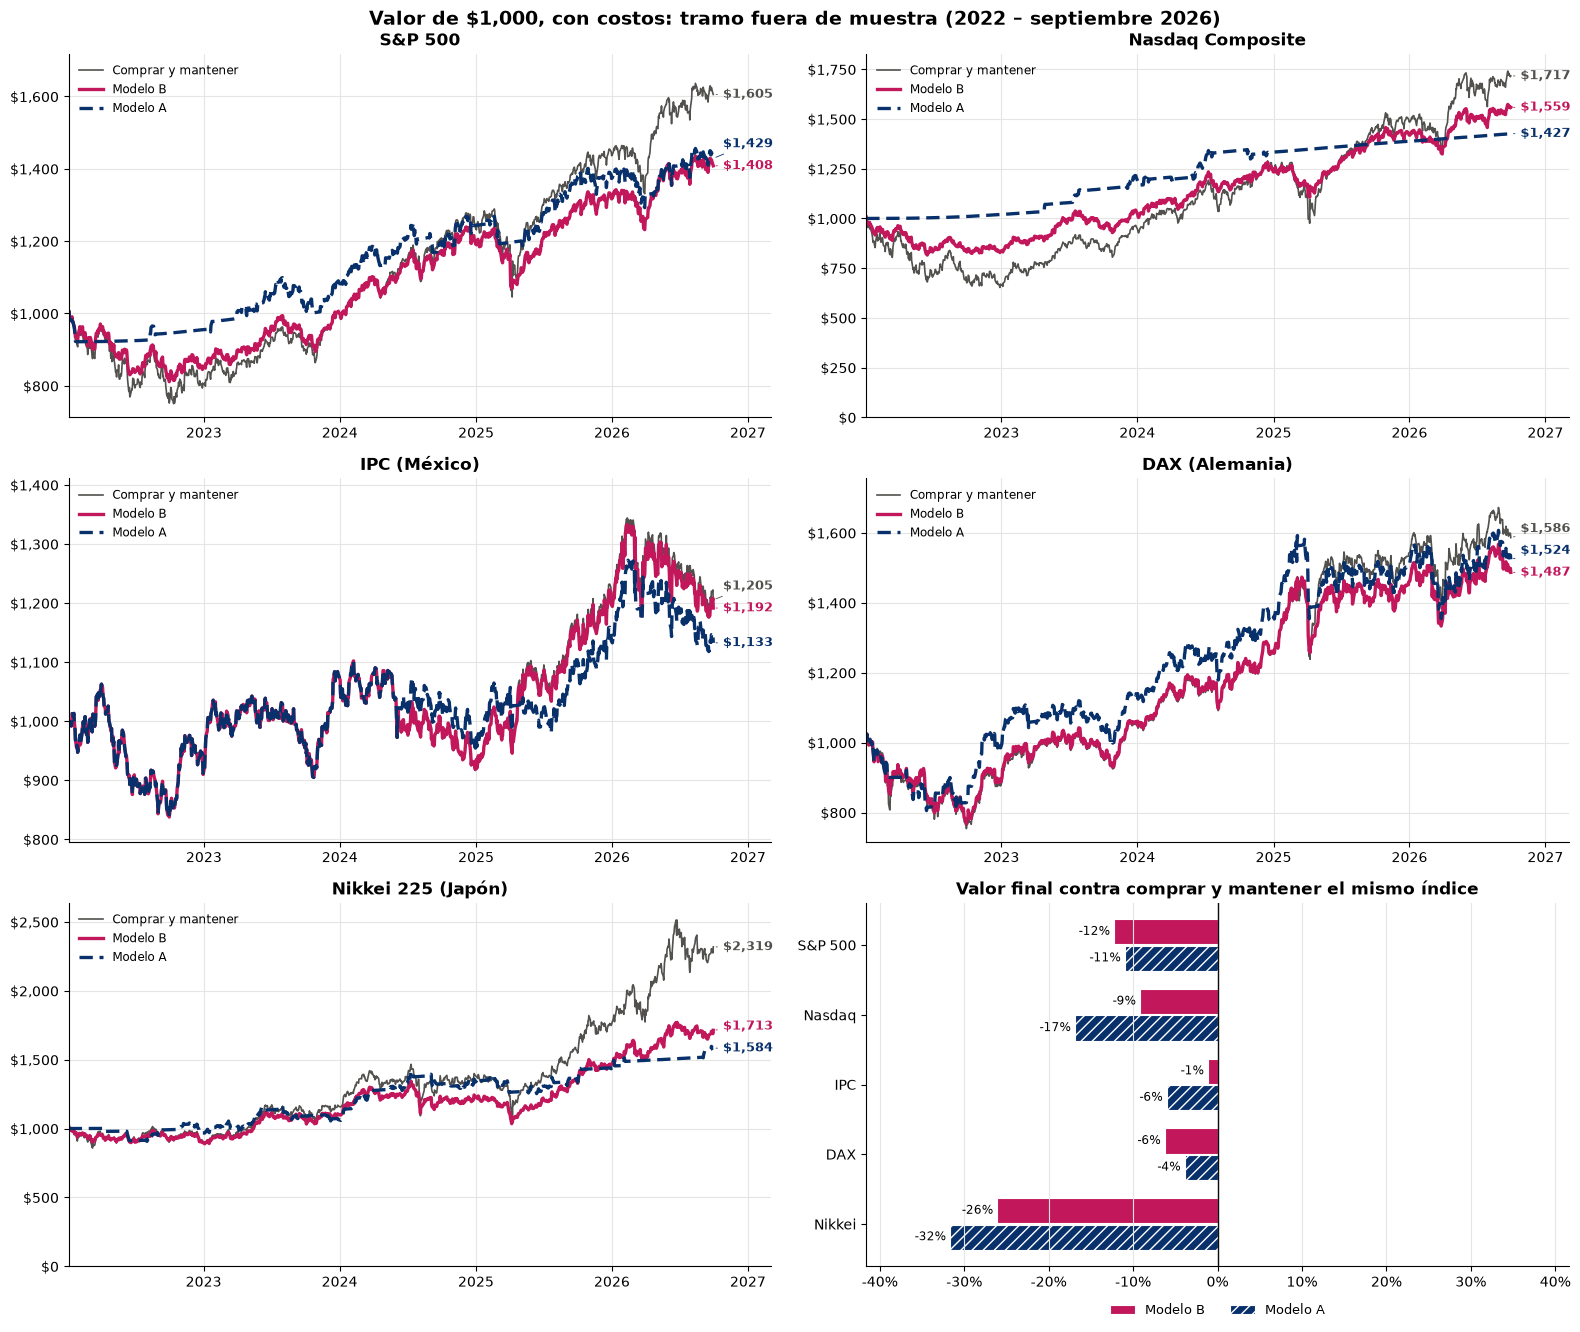

In [24]:
def estilo_lineas(a):
    # Secundaria a color: A punteado, así no depende sólo del tono
    for l in a.get_lines():
        if l.get_label() == "Modelo A":
            l.set_linestyle((0, (4, 2)))
    a.legend(loc="upper left", fontsize=8.5)


fig, ax = plt.subplots(3, 2, figsize=(16, 13.5))
for a, t in zip(ax.flat, TICKERS):
    grafica_valor(a, {n: ACT[t]["rr"][n][0] for n in ESTRATEGIAS}, NOMBRE[t], resaltar=["Modelo A", "Modelo B"])
    estilo_lineas(a)
a = ax.flat[-1]
y = np.arange(len(TICKERS))
for n, desp in [("Modelo B", -0.19), ("Modelo A", 0.19)]:
    rel = [ACT[t]["tab"].loc[n, "valor final"] / ACT[t]["tab"].loc["Comprar y mantener", "valor final"] - 1 for t in TICKERS]
    barras = a.barh(y + desp, rel, 0.36, color=C_EST[n], label=n, hatch="///" if n == "Modelo A" else None,
                    edgecolor="white", linewidth=0.8)
    a.bar_label(barras, labels=[f"{v:+.0%}" for v in rel], padding=3, fontsize=8.5)
a.axvline(0, color="#0b0b0b", lw=1)
a.set_yticks(y, [NOMBRE_CORTO[t] for t in TICKERS]); a.invert_yaxis()
a.xaxis.set_major_formatter(pct); a.grid(axis="y", visible=False)
lim = max(abs(v) for v in a.get_xlim()) * 1.25; a.set_xlim(-lim, lim)
a.set_title("Valor final contra comprar y mantener el mismo índice")
a.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2, fontsize=9)
fig.suptitle(f"Valor de $1,000, con costos: {TITULO_OOT}", fontsize=14, fontweight="bold")
plt.tight_layout(); fig.savefig("figuras/B1a_valor.png", dpi=200, bbox_inches="tight"); plt.show()

### Caída desde el máximo

La otra mitad de la historia: cuánto se llegó a perder desde el máximo previo. El último panel compara la peor caída de cada estrategia en cada índice.

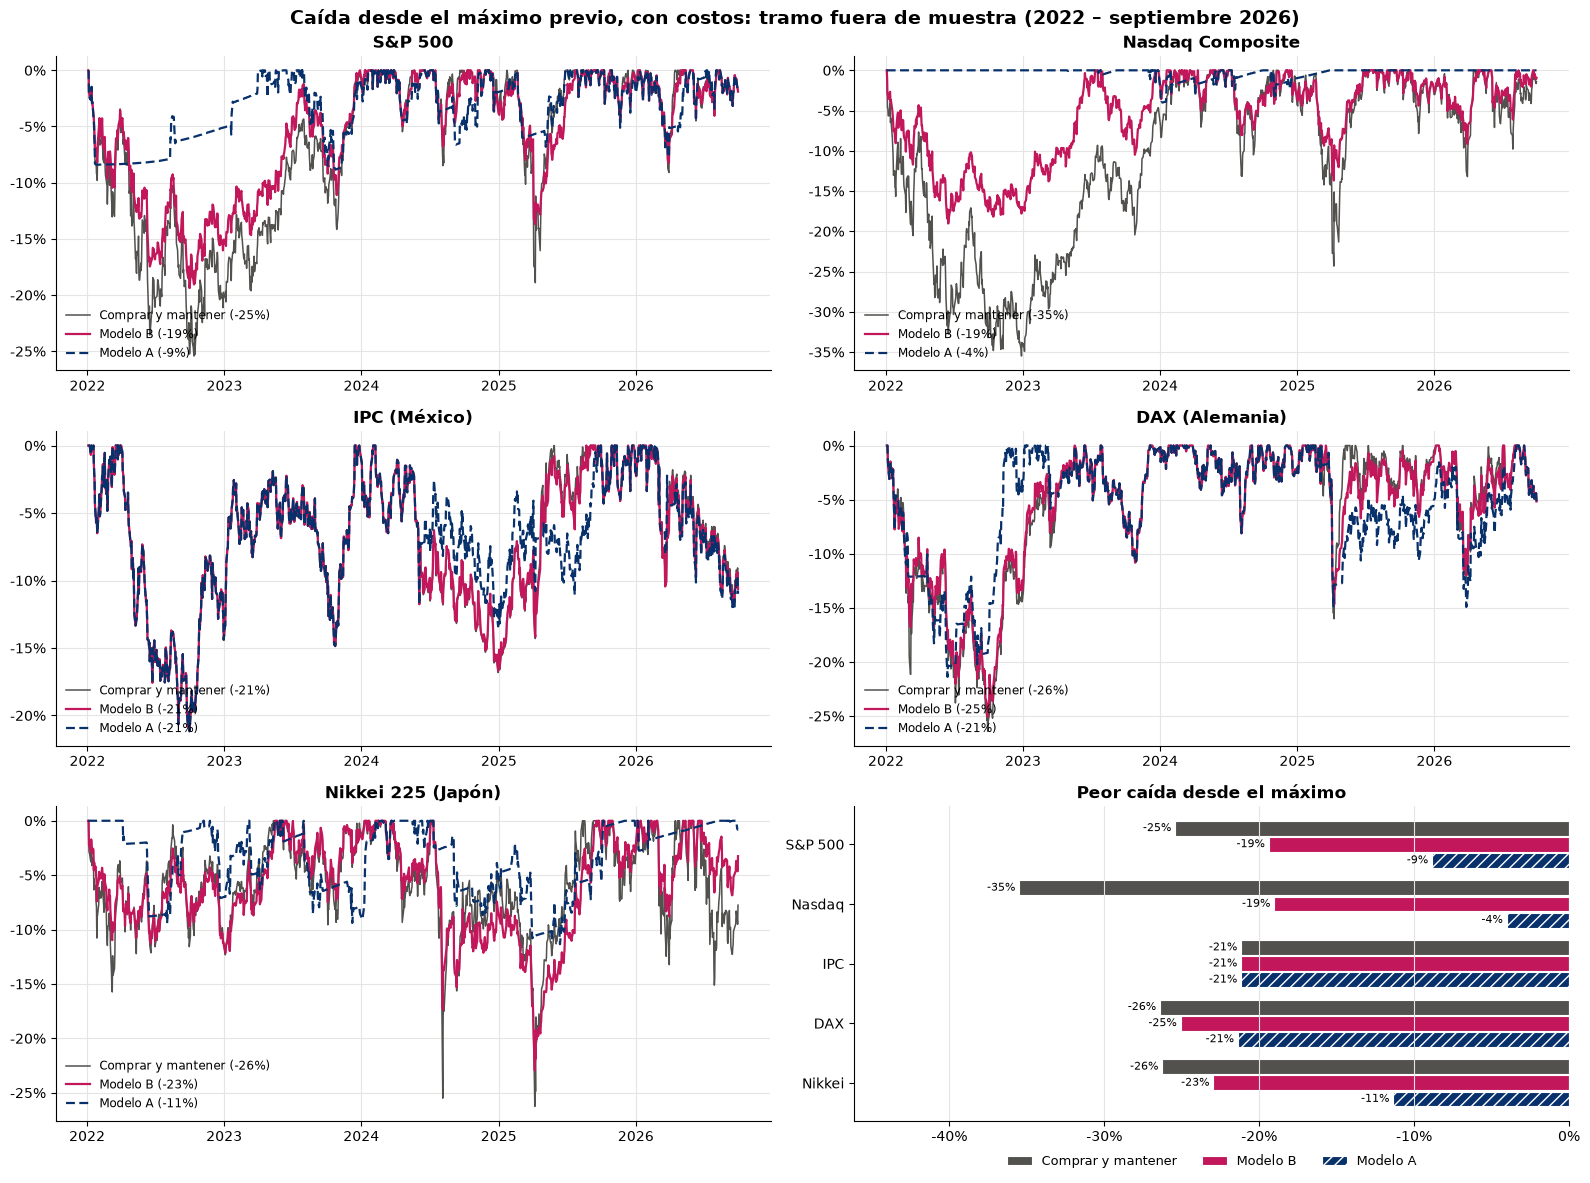

In [25]:
fig, ax = plt.subplots(3, 2, figsize=(16, 12))
peores = {}
for a, t in zip(ax.flat, TICKERS):
    for n in ESTRATEGIAS:
        riq = (1 + ACT[t]["rr"][n][0]).cumprod()
        dd = riq / riq.cummax() - 1
        peores[(t, n)] = dd.min()
        a.plot(dd, color=C_EST[n], lw=1.1 if n == "Comprar y mantener" else 1.6, label=f"{n} ({dd.min():.0%})",
               ls=(0, (4, 2)) if n == "Modelo A" else "-")
    a.yaxis.set_major_formatter(pct); a.legend(loc="lower left", fontsize=8.5); a.set_title(NOMBRE[t])
a = ax.flat[-1]
y = np.arange(len(TICKERS))
for n, desp in [("Comprar y mantener", -0.27), ("Modelo B", 0.0), ("Modelo A", 0.27)]:
    v = [peores[(t, n)] for t in TICKERS]
    b = a.barh(y + desp, v, 0.25, color=C_EST[n], label=n, hatch="///" if n == "Modelo A" else None, edgecolor="white", linewidth=0.8)
    a.bar_label(b, labels=[f"{x:.0%}" for x in v], padding=3, fontsize=8)
a.set_yticks(y, [NOMBRE_CORTO[t] for t in TICKERS]); a.invert_yaxis(); a.xaxis.set_major_formatter(pct)
a.set_xlim(min(peores.values()) * 1.3, 0); a.grid(axis="y", visible=False)
a.set_title("Peor caída desde el máximo"); a.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=3, fontsize=9)
fig.suptitle(f"Caída desde el máximo previo, con costos: {TITULO_OOT}", fontsize=14, fontweight="bold")
plt.tight_layout(); fig.savefig("figuras/B1b_caidas.png", dpi=200, bbox_inches="tight"); plt.show()

## B.2 Tabla de métricas

**Qué mide cada columna** (todas con costos):

| Métrica | Qué dice | Mejor si |
|---|---|---|
| Valor final, rendimiento anual | Cuánto dinero se hizo | más alto |
| Volatilidad anual | Qué tanto se mueve el portafolio | más baja |
| Sharpe | Rendimiento sobre T-bills por unidad de volatilidad | más alto |
| Sortino | Como el Sharpe, pero sólo castiga los días malos | más alto |
| Caída máxima | La peor pérdida desde un máximo | menos negativa |
| Calmar | Rendimiento anual entre la caída máxima: cuánto se gana por cada punto de la peor pérdida | más alto |
| Exposición media, rotación | Cuánto se invierte en promedio y cuánto se mueve la posición | — |
| PSR | Probabilidad de que el Sharpe verdadero sea mayor que cero [14] | más alto |

En cada índice se marca en verde la mejor de las tres estrategias en volatilidad, Sharpe, Sortino, caída máxima y Calmar. La tabla se guarda en `tablas/` como CSV.

In [26]:
COLS_M = ["valor final", "rend. anual", "vol. anual", "Sharpe", "Sortino", "caída máxima", "Calmar", "exposición media",
          "rotación anual", "PSR"]
ETIQ_M = {**ETIQ, "Sortino": "Sortino", "Calmar": "Calmar", "PSR": "PSR"}
FMT_M = {**{ETIQ[c]: FMT_RES[c] for c in COLS_M if c in FMT_RES}, "Sortino": "{:.2f}", "Calmar": "{:.2f}", "PSR": "{:.2f}"}
MEJOR = {"vol. anual": "min", "Sharpe": "max", "Sortino": "max", "caída máxima": "max", "Calmar": "max"}
VERDE = "background-color: #d7eedf; color: #0b0b0b; font-weight: bold"      # texto oscuro: se lee en tema claro y oscuro


def marcar(col):
    estilos = pd.Series("", index=col.index)
    if col.name not in MEJOR:
        return estilos
    for activo in col.index.get_level_values(0).unique():
        sub = col.xs(activo, level=0)
        gana = sub.idxmax() if MEJOR[col.name] == "max" else sub.idxmin()
        estilos[(activo, gana)] = VERDE
    return estilos


METRICAS = pd.concat({NOMBRE[t]: ACT[t]["tab"].loc[ESTRATEGIAS, COLS_M] for t in TICKERS})
METRICAS.to_csv("tablas/B2_metricas_fuera_de_muestra.csv", encoding="utf-8-sig")
print(f"Tabla B.1. Métricas con costos, {TITULO_OOT}")
display(METRICAS.style.apply(marcar).format({c: FMT_M[ETIQ_M[c]] for c in METRICAS.columns}).relabel_index(
    [ETIQ_M[c] for c in METRICAS.columns], axis=1))

Tabla B.1. Métricas con costos, tramo fuera de muestra (2022 – septiembre 2026)


## B.3 Diferencias contra comprar y mantener

La misma información, ahora como **diferencia contra comprar y mantener el mismo índice**. Así se compara directamente lo que cada modelo cambia en cada mercado. En verde lo que mejora frente al índice y en rojo lo que empeora; el p-valor es el de la prueba pareada de Ledoit y Wolf [16] para la diferencia de Sharpe.

- **Rendimiento (puntos):** rendimiento anual del modelo menos el del índice.
- **Volatilidad (relativa):** −20% quiere decir 20% menos volatilidad que el índice.
- **Caída ahorrada (puntos):** +10 puntos quiere decir que la peor caída fue 10 puntos menor.

In [27]:
filas = {}
for t in TICKERS:
    tab_, lw = ACT[t]["tab"], ACT[t]["lw"]
    bh = tab_.loc["Comprar y mantener"]
    fila = {}
    for n in ["Modelo B", "Modelo A"]:
        m, l = tab_.loc[n], lw.loc[f"{n} − Comprar y mantener"]
        fila.update({(n, "Rendimiento (puntos)"): m["rend. anual"] - bh["rend. anual"],
                     (n, "Volatilidad (relativa)"): m["vol. anual"] / bh["vol. anual"] - 1,
                     (n, "Caída ahorrada (puntos)"): m["caída máxima"] - bh["caída máxima"],
                     (n, "Δ Sharpe"): l["diferencia"], (n, "EE pareado"): l["EE pareado"], (n, "p-valor"): l["p-valor"],
                     (n, "Δ Calmar"): m["Calmar"] - bh["Calmar"]})
    filas[NOMBRE[t]] = fila
DIF = pd.DataFrame(filas).T

SIGNO_BUENO = {"Rendimiento (puntos)": 1, "Volatilidad (relativa)": -1, "Caída ahorrada (puntos)": 1, "Δ Sharpe": 1, "Δ Calmar": 1}
FMT_D = {"Rendimiento (puntos)": "{:+.1%}", "Volatilidad (relativa)": "{:+.0%}", "Caída ahorrada (puntos)": "{:+.1%}",
         "Δ Sharpe": "{:+.2f}", "EE pareado": "{:.2f}", "p-valor": "{:.2f}", "Δ Calmar": "{:+.2f}"}


def color_dif(col):
    s = SIGNO_BUENO.get(col.name[1])
    if s is None:
        return [""] * len(col)
    return ["" if pd.isna(v) or v == 0 else
            ("background-color: #d7eedf; color: #0b0b0b" if v * s > 0 else "background-color: #f8d9d6; color: #0b0b0b") for v in col]


DIF.to_csv("tablas/B3_diferencias_fuera_de_muestra.csv", encoding="utf-8-sig")
print(f"Tabla B.2. Diferencias contra comprar y mantener, con costos, {TITULO_OOT}")
display(DIF.style.apply(color_dif).format({c: FMT_D[c[1]] for c in DIF.columns}))

Tabla B.2. Diferencias contra comprar y mantener, con costos, tramo fuera de muestra (2022 – septiembre 2026)


## B.4 Patrones entre índices

Tres gráficas para buscar lo que se repite de un mercado a otro.

1. **Riesgo que se quita contra rendimiento que se cede.** Cada punto es un modelo en un índice. Si los modelos funcionan como esperamos, los puntos caen a la izquierda (menos volatilidad) y cerca de la línea horizontal (sin ceder mucho rendimiento).
2. **Diferencia de Sharpe con su intervalo de 95%.** Si el intervalo cruza el cero, la diferencia contra el índice no es significativa.
3. **¿Qué tan agitado estuvo cada mercado respecto a su propia calibración?** El eje horizontal es la volatilidad realizada del índice en el tramo entre su σ* (la de su periodo de estimación). Un mercado más agitado que su calibración hace que A salga más y que B invierta menos.

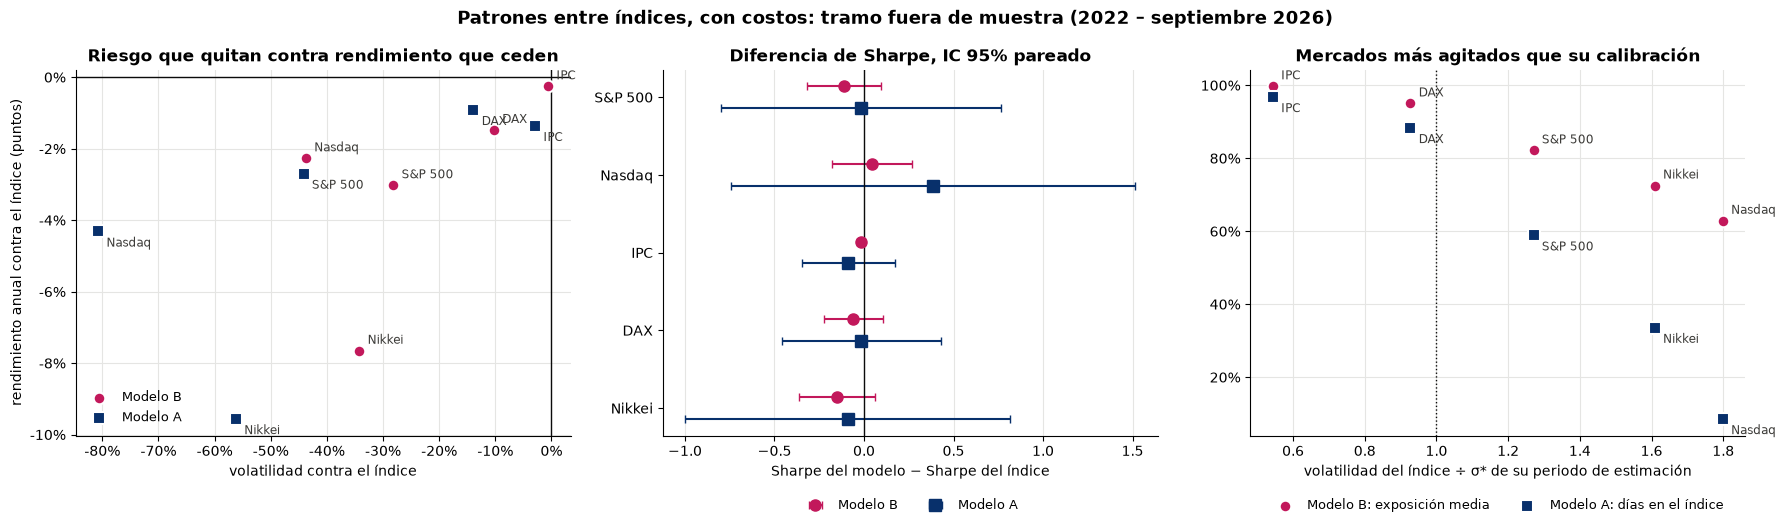

In [28]:
MARCA = {"Modelo B": "o", "Modelo A": "s"}
fig, ax = plt.subplots(1, 3, figsize=(18, 5.4))

a = ax[0]
for n in ["Modelo B", "Modelo A"]:
    xs, ys = DIF[(n, "Volatilidad (relativa)")].values, DIF[(n, "Rendimiento (puntos)")].values
    a.scatter(xs, ys, s=70, marker=MARCA[n], color=C_EST[n], edgecolor="white", linewidth=1.5, label=n, zorder=3)
    for xv, yv, t in zip(xs, ys, TICKERS):
        a.annotate(NOMBRE_CORTO[t], (xv, yv), xytext=(6, 5) if n == "Modelo B" else (6, -11), textcoords="offset points",
                   fontsize=8.5, color="#3b3a37")
a.axhline(0, color="#0b0b0b", lw=1); a.axvline(0, color="#0b0b0b", lw=1)
a.xaxis.set_major_formatter(pct); a.yaxis.set_major_formatter(pct)
a.set_xlabel("volatilidad contra el índice"); a.set_ylabel("rendimiento anual contra el índice (puntos)")
a.set_title("Riesgo que quitan contra rendimiento que ceden"); a.legend(loc="best", fontsize=9)

a = ax[1]
y = np.arange(len(TICKERS))
for n, desp in [("Modelo B", -0.14), ("Modelo A", 0.14)]:
    a.errorbar(DIF[(n, "Δ Sharpe")].values, y + desp, xerr=1.96 * DIF[(n, "EE pareado")].values, fmt=MARCA[n], color=C_EST[n],
               ms=8, capsize=3, lw=1.5, label=n)
a.axvline(0, color="#0b0b0b", lw=1)
a.set_yticks(y, [NOMBRE_CORTO[t] for t in TICKERS]); a.invert_yaxis(); a.grid(axis="y", visible=False)
a.set_xlabel("Sharpe del modelo − Sharpe del índice"); a.set_title("Diferencia de Sharpe, IC 95% pareado")
a.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9)

a = ax[2]
agit = {t: ACT[t]["tab"].loc["Comprar y mantener", "vol. anual"] / ACT[t]["vol_objetivo"] for t in TICKERS}
for n, col in [("Modelo B", "exposición media"), ("Modelo A", "% comprado")]:
    xs, ys = [agit[t] for t in TICKERS], [ACT[t]["tab"].loc[n, col] for t in TICKERS]
    a.scatter(xs, ys, s=70, marker=MARCA[n], color=C_EST[n], edgecolor="white", linewidth=1.5, zorder=3,
              label=f"{n}: {'exposición media' if n == 'Modelo B' else 'días en el índice'}")
    for xv, yv, t in zip(xs, ys, TICKERS):
        a.annotate(NOMBRE_CORTO[t], (xv, yv), xytext=(6, 5) if n == "Modelo B" else (6, -11), textcoords="offset points",
                   fontsize=8.5, color="#3b3a37")
a.axvline(1, color="#0b0b0b", lw=1, ls=":")
a.yaxis.set_major_formatter(pct); a.set_xlabel("volatilidad del índice ÷ σ* de su periodo de estimación")
a.set_title("Mercados más agitados que su calibración")
a.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9)
fig.suptitle(f"Patrones entre índices, con costos: {TITULO_OOT}", fontsize=13, fontweight="bold")
plt.tight_layout(); fig.savefig("figuras/B4_patrones.png", dpi=200, bbox_inches="tight"); plt.show()

### Patrones en cifras

Un resumen automático de lo que se repite entre índices. Son conteos y medianas sobre cinco índices: sirven para **describir** patrones, no para probarlos (la prueba formal está en D.1). Las correlaciones con cinco puntos son sólo indicativas.

In [29]:
n_ = len(TICKERS)
for n in ["Modelo B", "Modelo A"]:
    v, c, s, p, r = (DIF[(n, k)] for k in ["Volatilidad (relativa)", "Caída ahorrada (puntos)", "Δ Sharpe", "p-valor", "Rendimiento (puntos)"])
    sig_ = [NOMBRE_CORTO[t] for t, ok in zip(TICKERS, p < CRITERIOS["alfa"]) if ok]
    print(f"{n}:\n  menos volatilidad que el índice en {(v < 0).sum()} de {n_} (mediana {v.median():+.0%})\n"
          f"  menor caída máxima en {(c > 0).sum()} de {n_} (mediana {c.median():+.1%} pts)\n"
          f"  Sharpe mayor que el índice en {(s > 0).sum()} de {n_} (mediana {s.median():+.2f}); "
          f"significativas al 5%: {', '.join(sig_) if sig_ else 'ninguna'}\n"
          f"  rendimiento anual contra el índice: mediana {r.median():+.1%} pts")
sb, sa = DIF[("Modelo B", "Δ Sharpe")], DIF[("Modelo A", "Δ Sharpe")]
print(f"B contra A: Sharpe de B mayor en {(sb > sa).sum()} de {n_}; caída de B menor en "
      f"{(DIF[('Modelo B', 'Caída ahorrada (puntos)')] > DIF[('Modelo A', 'Caída ahorrada (puntos)')]).sum()} de {n_}")
vol_idx = np.array([ACT[t]["tab"].loc["Comprar y mantener", "vol. anual"] for t in TICKERS])
ag = np.array([agit[t] for t in TICKERS])
print(f"Correlaciones entre índices (n = {n_}, indicativas): volatilidad del índice con la Δ Sharpe de B "
      f"{np.corrcoef(vol_idx, sb)[0, 1]:+.2f}; agitación relativa (vol ÷ σ*) con la Δ Sharpe de A {np.corrcoef(ag, sa)[0, 1]:+.2f}; "
      f"agitación relativa con la caída ahorrada por B {np.corrcoef(ag, DIF[('Modelo B', 'Caída ahorrada (puntos)')])[0, 1]:+.2f}")

Modelo B:
  menos volatilidad que el índice en 5 de 5 (mediana -28%)
  menor caída máxima en 4 de 5 (mediana +3.3% pts)
  Sharpe mayor que el índice en 1 de 5 (mediana -0.06); significativas al 5%: ninguna
  rendimiento anual contra el índice: mediana -2.3% pts
Modelo A:
  menos volatilidad que el índice en 5 de 5 (mediana -44%)
  menor caída máxima en 4 de 5 (mediana +14.9% pts)
  Sharpe mayor que el índice en 1 de 5 (mediana -0.02); significativas al 5%: ninguna
  rendimiento anual contra el índice: mediana -2.7% pts
B contra A: Sharpe de B mayor en 1 de 5; caída de B menor en 0 de 5
Correlaciones entre índices (n = 5, indicativas): volatilidad del índice con la Δ Sharpe de B -0.03; agitación relativa (vol ÷ σ*) con la Δ Sharpe de A +0.62; agitación relativa con la caída ahorrada por B +0.78


# C. Por qué: diagnóstico por índice

Esta sección explica los resultados de B: cómo vio el detector a cada mercado, si se cumplió ahí la premisa del modelo B y qué pasó en cada caída del tramo fuera de muestra.

## C.1 La escala de cada mercado

**Por qué lo preguntamos.** Los umbrales de A y la σ* de B vienen del periodo de estimación de cada índice, que tiene su propio carácter: el IPC estima con la crisis de 1994–1995 y el Nikkei con la burbuja de los ochenta. Si 2022–2026 fue más agitado que esa calibración, A pasa más tiempo fuera y B invierte menos. Esta tabla lo muestra.

Tabla C.1. Etiquetas ancladas, exposición y escala de cada índice, tramo fuera de muestra (2022 – septiembre 2026)


,Días alcista,Días base,Días bajista,Exposición media de B,Días de A en el índice,Volatilidad del índice,σ* de B,Umbral bajista
S&P 500,0%,52%,48%,82%,59%,17.2%,13.5%,16.4%
Nasdaq Composite,0%,5%,95%,63%,9%,23.0%,12.8%,13.5%
IPC (México),32%,64%,5%,100%,97%,15.8%,29.1%,24.8%
DAX (Alemania),3%,80%,17%,95%,88%,17.1%,18.4%,20.3%
Nikkei 225 (Japón),0%,24%,76%,73%,34%,23.5%,14.6%,17.5%


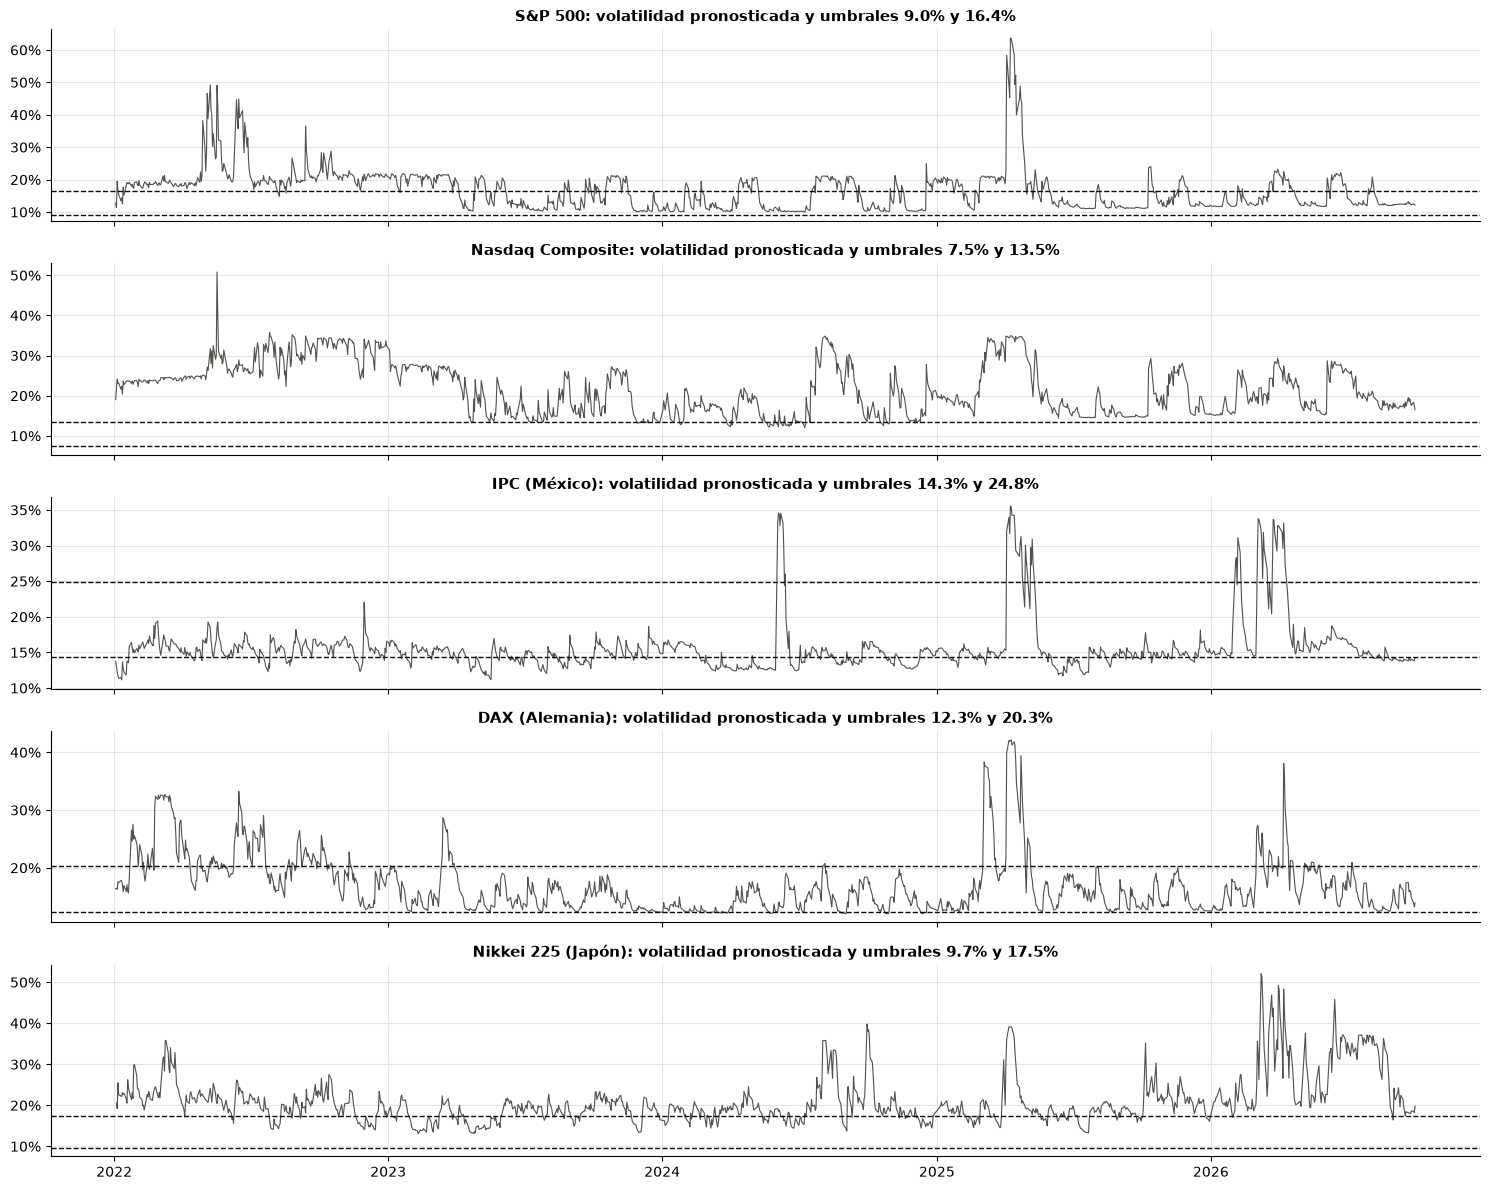

In [30]:
filas = {}
for t in TICKERS:
    et, tab_ = ACT[t]["et"], ACT[t]["tab"]
    filas[NOMBRE[t]] = {**{f"Días {n}": (et == i).mean() for i, n in enumerate(NOMBRES)},
                        "Exposición media de B": tab_.loc["Modelo B", "exposición media"],
                        "Días de A en el índice": tab_.loc["Modelo A", "% comprado"],
                        "Volatilidad del índice": tab_.loc["Comprar y mantener", "vol. anual"],
                        "σ* de B": ACT[t]["vol_objetivo"], "Umbral bajista": ACT[t]["umbrales"][1]}
tabla_esc = pd.DataFrame(filas).T
tabla_esc.to_csv("tablas/C1_escala.csv", encoding="utf-8-sig")
print(f"Tabla C.1. Etiquetas ancladas, exposición y escala de cada índice, {TITULO_OOT}")
display(tabla_esc.style.format({c: ("{:.1%}" if c in ("Volatilidad del índice", "σ* de B", "Umbral bajista") else "{:.0%}")
                                for c in tabla_esc.columns}))

fig, ax = plt.subplots(len(TICKERS), 1, figsize=(15, 2.4 * len(TICKERS)), sharex=True)
for a, t in zip(ax, TICKERS):
    a.plot(ACT[t]["sig"], color="#52514e", lw=0.8)
    for u in ACT[t]["umbrales"]:
        a.axhline(u, color="#0b0b0b", ls="--", lw=1)
    a.yaxis.set_major_formatter(pct)
    a.set_title(f"{NOMBRE[t]}: volatilidad pronosticada y umbrales {ACT[t]['umbrales'][0]:.1%} y {ACT[t]['umbrales'][1]:.1%}",
                fontsize=10.5)
plt.tight_layout(); fig.savefig("figuras/C1_volatilidad_pronosticada.png", dpi=200, bbox_inches="tight"); plt.show()

## C.2 La premisa de Moreira y Muir en cada mercado

**Por qué lo preguntamos.** El modelo B supone que, cuando sube la volatilidad pronosticada, el rendimiento esperado no sube en la misma proporción [15]. En el S&P esa premisa se cumplió sólo a medias (Q3 del Reporte 5) y Cederburg et al. [17] advierten que es frágil fuera de muestra. Si en un índice el rendimiento por unidad de volatilidad no baja de los días tranquilos a los agitados, no hay que esperar que B mejore el Sharpe ahí; a lo más, que reduzca el riesgo.

**Cómo se lee.** Los días del tramo fuera de muestra se dividen en quintiles de volatilidad pronosticada (Q1 tranquilos, Q5 agitados), unos 240 días por quintil. Cada celda es el rendimiento anual del índice entre su volatilidad realizada en ese quintil. Las dos primeras columnas confirman que el detector sí ordena la volatilidad. Con menos de cinco años, cada celda es ruidosa: hay que leer la tendencia, no cada número.

In [31]:
filas = {}
for t in TICKERS:
    sig = ACT[t]["sig"]
    r_lag = DATOS[t]["r_simple"].shift(-H).reindex(sig.index)
    q = pd.qcut(sig, 5, labels=["Q1 (calma)", "Q2", "Q3", "Q4", "Q5 (agitado)"])
    fila = {"Vol. real Q1": r_lag[q == "Q1 (calma)"].std() * np.sqrt(252), "Vol. real Q5": r_lag[q == "Q5 (agitado)"].std() * np.sqrt(252)}
    fila.update({k: r_lag[q == k].mean() * 252 / (r_lag[q == k].std() * np.sqrt(252)) for k in q.cat.categories})
    filas[NOMBRE[t]] = fila
tabla_premisa = pd.DataFrame(filas).T
tabla_premisa.to_csv("tablas/C2_premisa.csv", encoding="utf-8-sig")
print(f"Tabla C.2. Rendimiento por unidad de volatilidad del índice en cada quintil de volatilidad pronosticada, {TITULO_OOT}")
display(tabla_premisa.style.format({c: ("{:.1%}" if c.startswith("Vol.") else "{:.2f}") for c in tabla_premisa.columns}))

Tabla C.2. Rendimiento por unidad de volatilidad del índice en cada quintil de volatilidad pronosticada, tramo fuera de muestra (2022 – septiembre 2026)


,Vol. real Q1,Vol. real Q5,Q1 (calma),Q2,Q3,Q4,Q5 (agitado)
S&P 500,11.0%,24.2%,0.57,0.90,0.86,-0.73,1.72
Nasdaq Composite,15.6%,31.9%,0.26,1.21,1.69,-0.18,0.56
IPC (México),15.8%,18.0%,-0.03,-1.04,0.76,0.42,1.38
DAX (Alemania),11.1%,24.8%,1.15,0.77,-0.32,0.93,0.71
Nikkei 225 (Japón),18.0%,35.0%,1.62,0.61,-0.50,0.84,1.46


## C.3 Episodios de caída

La misma regla del examen del S&P: un episodio es una caída del índice de al menos 10% desde su máximo previo. *Protección* es la fracción de la caída del índice que se ahorró cada modelo entre el máximo y el mínimo; *rebote*, el rendimiento de los 63 días hábiles siguientes al mínimo. *Velocidad* es la caída del índice entre los días que tardó en llegar al mínimo: sirve para ver si los modelos protegen más en las caídas rápidas, como en el S&P.

In [32]:
filas = []
for t in TICKERS:
    riq = {n: INICIAL * (1 + ACT[t]["rr"][n][0]).cumprod() for n in ESTRATEGIAS}
    for _, e in episodios_caida(riq["Comprar y mantener"], CRITERIOS["caida_episodio"]).iterrows():
        a, b = e["máximo"], e["mínimo"]
        dias = len(riq["Comprar y mantener"][a:b]) - 1
        fila = {"Índice": NOMBRE_CORTO[t], "Máximo": f"{a:%Y-%m-%d}", "Mínimo": f"{b:%Y-%m-%d}", "Días al mínimo": dias,
                "Caída del índice": e["caída del índice"], "Velocidad (%/día)": -e["caída del índice"] / max(dias, 1)}
        for n, k in [("Modelo B", "B"), ("Modelo A", "A")]:
            tramo_ = riq[n][a:b]
            fila[f"Protección {k}"] = 1 - ((tramo_ / tramo_.iloc[0]).min() - 1) / e["caída del índice"]
        despues = riq["Comprar y mantener"].index[riq["Comprar y mantener"].index > b][:CRITERIOS["dias_rebote"]]
        for n, k in [("Comprar y mantener", "índice"), ("Modelo B", "B"), ("Modelo A", "A")]:
            fila[f"Rebote {k}"] = riq[n][despues[-1]] / riq[n][b] - 1 if len(despues) == CRITERIOS["dias_rebote"] else np.nan
        filas.append(fila)
tabla_eps_m = pd.DataFrame(filas)
tabla_eps_m.to_csv("tablas/C3_episodios.csv", encoding="utf-8-sig", index=False)
print(f"Tabla C.3. Caídas de al menos {CRITERIOS['caida_episodio']:.0%}, con costos, {TITULO_OOT}")
if len(tabla_eps_m):
    fmt = {c: "{:+.1%}" for c in tabla_eps_m.columns if c.startswith(("Caída", "Rebote"))}
    fmt.update({c: "{:.0%}" for c in tabla_eps_m.columns if c.startswith("Protección")})
    fmt["Velocidad (%/día)"] = "{:.2%}"
    display(tabla_eps_m.style.format(fmt, na_rep="—").hide(axis="index"))
    print("— : el mínimo quedó a menos de 63 días hábiles del fin del tramo; su rebote no se mide.")
    if len(tabla_eps_m) >= 3:
        for k in ["A", "B"]:
            rho = stats.spearmanr(tabla_eps_m["Velocidad (%/día)"], tabla_eps_m[f"Protección {k}"]).correlation
            print(f"Correlación de rangos entre la velocidad de la caída y la protección de {k}: {rho:+.2f} "
                  f"({len(tabla_eps_m)} episodios en los cinco índices)")
        reb = tabla_eps_m.dropna(subset=["Rebote A"])
        print(f"A rinde menos que el índice en {(reb['Rebote A'] < reb['Rebote índice']).sum()} de {len(reb)} rebotes; "
              f"B, en {(reb['Rebote B'] < reb['Rebote índice']).sum()} de {len(reb)}.")
else:
    print("Ningún índice cayó 10% o más en el tramo.")

Tabla C.3. Caídas de al menos 10%, con costos, tramo fuera de muestra (2022 – septiembre 2026)


Índice,Máximo,Mínimo,Días al mínimo,Caída del índice,Velocidad (%/día),Protección B,Protección A,Rebote índice,Rebote B,Rebote A
S&P 500,2022-01-03,2022-10-12,195,-25.4%,0.13%,24%,67%,+11.4%,+7.3%,+1.0%
S&P 500,2025-02-19,2025-04-08,34,-18.9%,0.56%,28%,68%,+26.0%,+14.5%,+7.8%
Nasdaq,2022-01-03,2022-12-28,248,-35.5%,0.14%,46%,100%,+17.6%,+9.0%,+1.2%
Nasdaq,2024-07-10,2024-08-07,20,-13.1%,0.66%,39%,82%,+13.9%,+5.5%,-0.6%
Nasdaq,2024-12-16,2025-04-08,76,-24.3%,0.32%,44%,100%,+35.1%,+18.0%,+1.1%
Nasdaq,2025-10-29,2026-03-30,103,-13.2%,0.13%,31%,100%,+26.1%,+14.3%,+0.9%
IPC,2022-04-01,2022-09-30,127,-21.2%,0.17%,0%,0%,+9.8%,+9.8%,+9.8%
IPC,2024-02-07,2024-12-30,224,-16.8%,0.08%,1%,20%,+9.2%,+9.2%,+9.2%
IPC,2026-02-11,2026-09-18,152,-11.5%,0.08%,-3%,-1%,—,—,—
DAX,2022-01-05,2022-09-29,189,-26.4%,0.14%,5%,19%,+16.3%,+15.6%,+19.0%


— : el mínimo quedó a menos de 63 días hábiles del fin del tramo; su rebote no se mide.
Correlación de rangos entre la velocidad de la caída y la protección de A: +0.24 (17 episodios en los cinco índices)
Correlación de rangos entre la velocidad de la caída y la protección de B: +0.45 (17 episodios en los cinco índices)
A rinde menos que el índice en 11 de 15 rebotes; B, en 12 de 15.


# D. Hipótesis y conclusiones

## D.1 Veredicto de las hipótesis

Cada hipótesis se evalúa en cada índice con el criterio declarado en la introducción, en el tramo fuera de muestra y con costos.

**Prueba de signos.** Si cada resultado fuera un volado (probabilidad 1/2), ¿qué tan raro sería que la hipótesis se cumpliera en tantos índices o más? Es la cola de la binomial: $p = P(X \ge k)$ con $X \sim \mathrm{Binomial}(n, 1/2)$.

In [33]:
def veredicto(cc, lw):
    bh, B, A = cc.loc["Comprar y mantener"], cc.loc["Modelo B"], cc.loc["Modelo A"]
    d = lw.loc["Modelo B − Comprar y mantener"]
    return {"HM1": B["vol. anual"] < bh["vol. anual"], "HM2": B["caída máxima"] > bh["caída máxima"],
            "HM3": not (d["diferencia"] < 0 and d["p-valor"] < CRITERIOS["alfa"]),
            "HM4": A["vol. anual"] < bh["vol. anual"] and A["caída máxima"] > bh["caída máxima"],
            "HM5": B["Sharpe"] >= A["Sharpe"]}


tabla_ver = pd.DataFrame({NOMBRE[t]: veredicto(ACT[t]["tab"], ACT[t]["lw"]) for t in TICKERS}).T[list(HIPOTESIS_M)].astype(bool)
n, k = len(tabla_ver), tabla_ver.sum()
resumen_ver = pd.DataFrame({"hipótesis": [HIPOTESIS_M[h] for h in HIPOTESIS_M], "se cumple en": [f"{k[h]} de {n}" for h in HIPOTESIS_M],
                            "p (prueba de signos)": [stats.binom.sf(k[h] - 1, n, 0.5) for h in HIPOTESIS_M]}, index=list(HIPOTESIS_M))
print(f"Tabla D.1. ¿En qué índices se cumple cada hipótesis? ({TITULO_OOT})")
display(tabla_ver.replace({True: "sí", False: "no"}))
display(resumen_ver.style.format({"p (prueba de signos)": "{:.3f}"}).set_properties(**{"text-align": "left"}))

Tabla D.1. ¿En qué índices se cumple cada hipótesis? (tramo fuera de muestra (2022 – septiembre 2026))


,HM1,HM2,HM3,HM4,HM5
S&P 500,sí,sí,sí,sí,no
Nasdaq Composite,sí,sí,sí,sí,no
IPC (México),sí,no,sí,no,sí
DAX (Alemania),sí,sí,sí,sí,no
Nikkei 225 (Japón),sí,sí,sí,sí,no


,hipótesis,se cumple en,p (prueba de signos)
HM1,B reduce la volatilidad: volatilidad anual de B menor que la del índice,5 de 5,0.031
HM2,B reduce la caída máxima: caída máxima de B menos severa que la del índice,4 de 5,0.188
HM3,B no sacrifica Sharpe: la diferencia B − índice no es negativa con p menor que 0.05 (Ledoit y Wolf),5 de 5,0.031
HM4,A reduce el riesgo: volatilidad y caída máxima de A menores que las del índice,4 de 5,0.188
HM5,B es al menos tan bueno como A: Sharpe de B mayor o igual que el de A,1 de 5,0.969


## D.2 Lectura: patrones y conclusiones

*Esta celda se escribe **después** de correr, con las cifras reales. Guía pensada para las secciones de resultados y conclusiones del paper:*

**Resultados**
- **¿Se generaliza el resultado central del S&P?** ¿En cuántos índices B reduce volatilidad y caída sin perder Sharpe significativamente? Citar las tablas B.1 y B.2, la gráfica de Sharpe de B.4 y la tabla D.1.
- **El costo de la protección.** ¿Cuánto rendimiento anual cede cada modelo por cada punto de volatilidad que quita? ¿Es parecido en todos los índices?
- **A contra B.** ¿El orden del S&P (B mejor que A) se repite en todos los mercados?
- **Las caídas (C.3).** ¿Se repite que protegen más en las caídas rápidas y que A pierde los rebotes?

**Patrones (por qué cambia de un mercado a otro)**
- **La escala (C.1 y tercera gráfica de B.4).** ¿Los mercados más agitados que su periodo de estimación son donde A pasa más tiempo fuera y le va peor?
- **La premisa (C.2).** ¿Los índices donde el rendimiento por unidad de volatilidad sí baja en Q5 son donde B mejora el Sharpe?

**Conclusiones y límites**
- Lo que se puede afirmar con cinco índices y menos de cinco años, y lo que no (prueba de signos de poco poder, índices correlacionados).
- La tasa libre de riesgo (el T-bill castiga al IPC y favorece al Nikkei y al DAX), los dividendos del DAX y la moneda local (introducción).
- Ningún resultado de este notebook cambia la regla: si un índice sale mal, se reporta así.

In [34]:
guardar_m = {"version": "v7", "tramo": "fuera de muestra (2022 – septiembre 2026)", "huella_declaracion": huella_decl,
             "aperturas": len(previas) + 1, "DECLARACION": DECLARACION, "huellas_datos": {t: d["huella"] for t, d in DATOS.items()},
             "calibracion": tabla_cal, "metricas": METRICAS, "diferencias": DIF, "escala": tabla_esc, "premisa": tabla_premisa,
             "episodios": tabla_eps_m, "veredicto": tabla_ver, "prueba_signos": resumen_ver,
             "rendimientos": {t: {n: v[0] for n, v in ACT[t]["rr"].items()} for t in TICKERS}}
with open("resultados_multiactivo_v7.pkl", "wb") as f:
    pickle.dump(guardar_m, f)
print("Guardado resultados_multiactivo_v7.pkl | figuras en figuras/ | tablas en tablas/")

Guardado resultados_multiactivo_v7.pkl | figuras en figuras/ | tablas en tablas/


## Bibliografía

[1] L. R. Rabiner, "A tutorial on hidden Markov models and selected applications in speech recognition," *Proceedings of the IEEE*, vol. 77, no. 2, pp. 257–286, 1989. http://www.cs.ubc.ca/~murphyk/Bayes/rabiner.pdf

[8] J. A. Climent Hernández, D. Rodríguez Benavides y R. Y. Castillo Dieguez, "Ingeniería financiera y portafolios óptimos con cambio de régimen," *Revista Mexicana de Economía y Finanzas*, vol. 20, no. 4, e1419, 2025. https://remef.org.mx/index.php/remef/article/view/1419

[9] J. Bulla, S. Mergner, I. Bulla, A. Sesboüé y C. Chesneau, "Markov-switching asset allocation: Do profitable strategies exist?," *Journal of Asset Management*, vol. 12, no. 5, pp. 310–321, 2011. https://mpra.ub.uni-muenchen.de/21154/

[11] J. Bulla, "Hidden Markov models with t components. Increased persistence and other aspects," *Quantitative Finance*, vol. 11, no. 3, pp. 459–475, 2011. https://mpra.ub.uni-muenchen.de/21830/1/MPRA_paper_21830.pdf

[14] D. H. Bailey y M. López de Prado, "The deflated Sharpe ratio," *Journal of Portfolio Management*, vol. 40, no. 5, pp. 94–107, 2014. http://www.davidhbailey.com/dhbpapers/deflated-sharpe.pdf

[15] A. Moreira y T. Muir, "Volatility-managed portfolios," *Journal of Finance*, vol. 72, no. 4, pp. 1611–1644, 2017. Versión de trabajo: NBER Working Paper 22208. https://www.nber.org/papers/w22208

[16] O. Ledoit y M. Wolf, "Robust performance hypothesis testing with the Sharpe ratio," *Journal of Empirical Finance*, vol. 15, no. 5, pp. 850–859, 2008.

[17] S. Cederburg, M. S. O'Doherty, F. Wang y X. S. Yan, "On the performance of volatility-managed portfolios," *Journal of Financial Economics*, vol. 138, no. 1, pp. 95–117, 2020.

La numeración sigue la del v5.1; las referencias que no se citan en este notebook se omiten.